In [1]:
# 图像分类数据集

import torch
import torchvision
from torch.utils import data
from torchvision import transforms
from d2l import torch as d2l

d2l.use_svg_display()

In [2]:
# 读取数据

trans = transforms.ToTensor()
mnist_train = torchvision.datasets.FashionMNIST(
    root="../data", train=True, transform=trans, download=True)
mnist_test = torchvision.datasets.FashionMNIST(
    root="../data", train=False, transform=trans, download=True)

In [3]:
trans, mnist_train, mnist_test

(ToTensor(),
 Dataset FashionMNIST
     Number of datapoints: 60000
     Root location: ../data
     Split: Train
     StandardTransform
 Transform: ToTensor(),
 Dataset FashionMNIST
     Number of datapoints: 10000
     Root location: ../data
     Split: Test
     StandardTransform
 Transform: ToTensor())

In [5]:
len(mnist_train), len(mnist_test), trans

(60000, 10000, ToTensor())

In [7]:
mnist_train[0][0].shape

torch.Size([1, 28, 28])

In [10]:
def get_fashion_mnist_labels(labels):  #@save
    """返回Fashion-MNIST数据集的文本标签"""
    text_labels = ['t-shirt', 'trouser', 'pullover', 'dress', 'coat',
                   'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot']
    return [text_labels[int(i)] for i in labels]

In [12]:
def show_images(imgs, num_rows, num_cols, titles=None, scale=1.5):  #@save
    """绘制图像列表"""
    figsize = (num_cols * scale, num_rows * scale)
    _, axes = d2l.plt.subplots(num_rows, num_cols, figsize=figsize)
    axes = axes.flatten()
    for i, (ax, img) in enumerate(zip(axes, imgs)):
        if torch.is_tensor(img):
            # 图片张量
            ax.imshow(img.numpy())
        else:
            # PIL图片
            ax.imshow(img)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        if titles:
            ax.set_title(titles[i])
    return axes

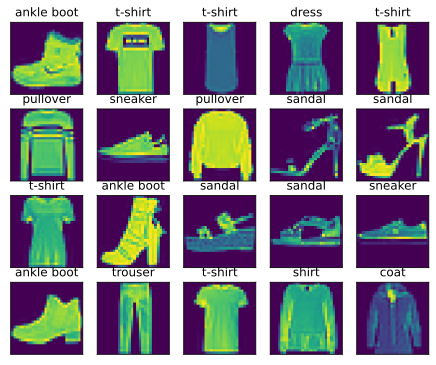

In [15]:
X, y = next(iter(data.DataLoader(mnist_train, batch_size=20)))
show_images(X.reshape(20, 28, 28), 4, 5, titles=get_fashion_mnist_labels(y));

In [16]:
# 读取小批量

batch_size = 256

def get_dataloader_workers():  #@save
    """使用4个进程来读取数据"""
    return 4

train_iter = data.DataLoader(mnist_train, batch_size, shuffle=True,
                             num_workers=get_dataloader_workers())

In [1]:
train_iter = data.DataLoader(mnist_train, batch_size, shuffle=True, num_workers=get_dataloader_workers())
for x, y in train_iter:
    print(x.shape, X.dtype, y.shape, y.dtype)
    show_images(x.reshape(256, 28, 28), 16, 16, titles=get_fashion_mnist_labels(y))
    break

NameError: name 'data' is not defined

In [26]:
import torch
from torch import nn
from d2l import torch as d2l

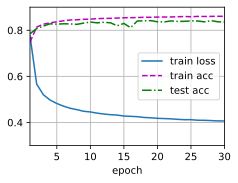

In [28]:
batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size) # 对 上面的 data.DataLoader 做了封装


net = nn.Sequential(nn.Flatten(), nn.Linear(28*28, 10))

loss = nn.CrossEntropyLoss(reduction='none')

trainer = torch.optim.SGD(net.parameters(), lr=0.11)

num_epochs = 30

d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)


tensor([-4.9152, -5.6052, -2.9846, -3.8221, -3.2298,  5.9374, -1.6494,  6.0134,
         2.9786,  7.5853], grad_fn=<SelectBackward0>)


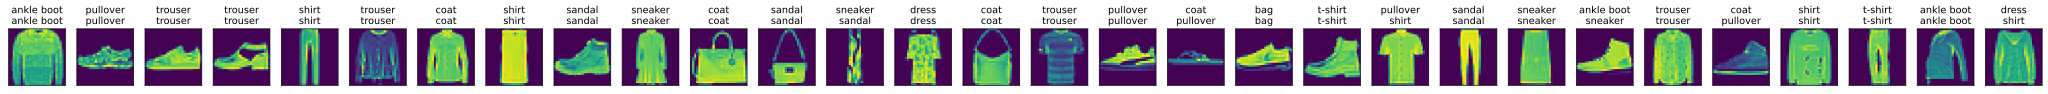

In [42]:
# 预测

def predict_ch3(net, test_iter, n=30):  #@save
    """预测标签（定义见第3章）"""
    for X, y in test_iter:
        break
    trues = d2l.get_fashion_mnist_labels(y)
    print(net(X))
    preds = d2l.get_fashion_mnist_labels(net(X).argmax(axis=1))
    titles = [true +'\n' + pred for true, pred in zip(trues, preds)]
    d2l.show_images(
        X[20:(n+20)].reshape((n, 28, 28)), 1, n, titles=titles[0:n])

predict_ch3(net, test_iter)